# Compare Pre-Emphasis

Compares no, fitting and optimisation pre-emphasis for the gradient and offset.

In [1]:
from matipo import GLOBALS_DIR
import panel as pn
import numpy as np
import pandas as pd
import copy
import matplotlib.pyplot as plt
plt.style.use('default')
import yaml
from pathlib import Path
import optuna
import shutil
import nest_asyncio
nest_asyncio.apply()

In [2]:
from user_interface.compare import Compare
scan_type = "compare_ec"
comp = Compare(scan_type)

In [3]:
flip_angle = 4.5
axis = "Y"

seq_params = {
    "OPT_AXIS": axis,
    "n_scans": 1,
    "a_pulse": comp.get_yaml_info("hardpulse_90_tx0.yaml")["a_90"],
    "t_pulse": (comp.get_yaml_info("hardpulse_90_tx0.yaml")["t_90"])*flip_angle/90,
    "t_dw": 10e-6,
    "n_samples": 100,
    "t_acq_delay": 100e-6,
    "t_grad": 10.0,
    "t_ramp": 1e-3,
    "t_wait": 8e-3,
    "n_pulses": 30,
    "t_end": 10.0,
    "t_next": 5,  # wait between scans
    "g_val": 0.1, # convert this into g_read before using
    "tx_chan": 0,
    "rx_chan_list": (3, 0, 1),
    "pre_emphasis": True,
    "b0": True,
    "file_cals": GLOBALS_DIR,
    "d_r": comp.get_yaml_info("probe_distances.yaml")["d_r"],
    "d_c": comp.get_yaml_info("probe_distances.yaml")["d_c"],
    "d_l": comp.get_yaml_info("probe_distances.yaml")["d_l"],

}

print(seq_params)

with open(GLOBALS_DIR+"g_hzpm_slope.yaml", "r") as f:
    cal_data = yaml.safe_load(f)
    print(cal_data)

{'OPT_AXIS': 'Y', 'n_scans': 1, 'a_pulse': 0.45, 't_pulse': 2.9999999999999997e-05, 't_dw': 1e-05, 'n_samples': 100, 't_acq_delay': 0.0001, 't_grad': 10.0, 't_ramp': 0.001, 't_wait': 0.008, 'n_pulses': 30, 't_end': 10.0, 't_next': 5, 'g_val': 0.1, 'tx_chan': 0, 'rx_chan_list': (3, 0, 1), 'pre_emphasis': True, 'b0': True, 'file_cals': 'C:\\Users\\halesda\\OneDrive - Victoria University of Wellington - STAFF\\Desktop\\kahu-workspace\\globals/', 'd_r': '5e-2', 'd_c': 0, 'd_l': '-5e-2'}
{'X': 1386806.596701649, 'Y': 2359703.084965453, 'Z': 1933006.7109302483}


In [4]:
start_path = GLOBALS_DIR

run_info = {
    "No_Compensation": 
        {
            "E_pars": None,
            "B_pars": None,
            "title": "No Compensation",
            "colour": "blue",
        },

    "Fitted_Compensation": 
        {
            "E_pars": "eddy_E_fit.yaml",
            "B_pars": "eddy_B0_fit.yaml",
            "title": "Fitted Compensation",
            "colour": "orange",
        },
        
    "Gradient_and_B0_Optimised_Compensation": 
        {
            "E_pars": "eddy_E.yaml",
            "B_pars": "eddy_B0.yaml",
            "title": "Gradient and B0 Optimised Compensation",
            "colour": "red",
        },
}

ParameterSet(n_scans=1, f=63637800.0, a_pulse=0.45, t_pulse=2.9999999999999997e-05, t_dw=1e-05, n_samples=100, n_pulses=30, t_acq_delay=0.0001, g_read=array([0. , 0.1, 0. ]), t_grad_spacing=1e-05, t_grad=10.0, t_ramp=0.001, t_wait=0.008, t_end=10.0, t_next=5.0, pre_emphasis=False, b0=False, offsets=array([0., 0., 0., 0.]), tx_chan=0, rx_chan_list=array([3., 0., 1.]), file_cals='C:\\Users\\halesda\\OneDrive - Victoria University of Wellington - STAFF\\Desktop\\kahu-workspace\\globals/', file_pars='C:\\Users\\halesda\\OneDrive - Victoria University of Wellington - STAFF\\Desktop\\kahu-workspace\\globals/', opt='n', compare='y', file_parsE='None', file_parsB='None')


DEBUG:measure:Pre-emphasis OFF
DEBUG:measure:B0 OFF


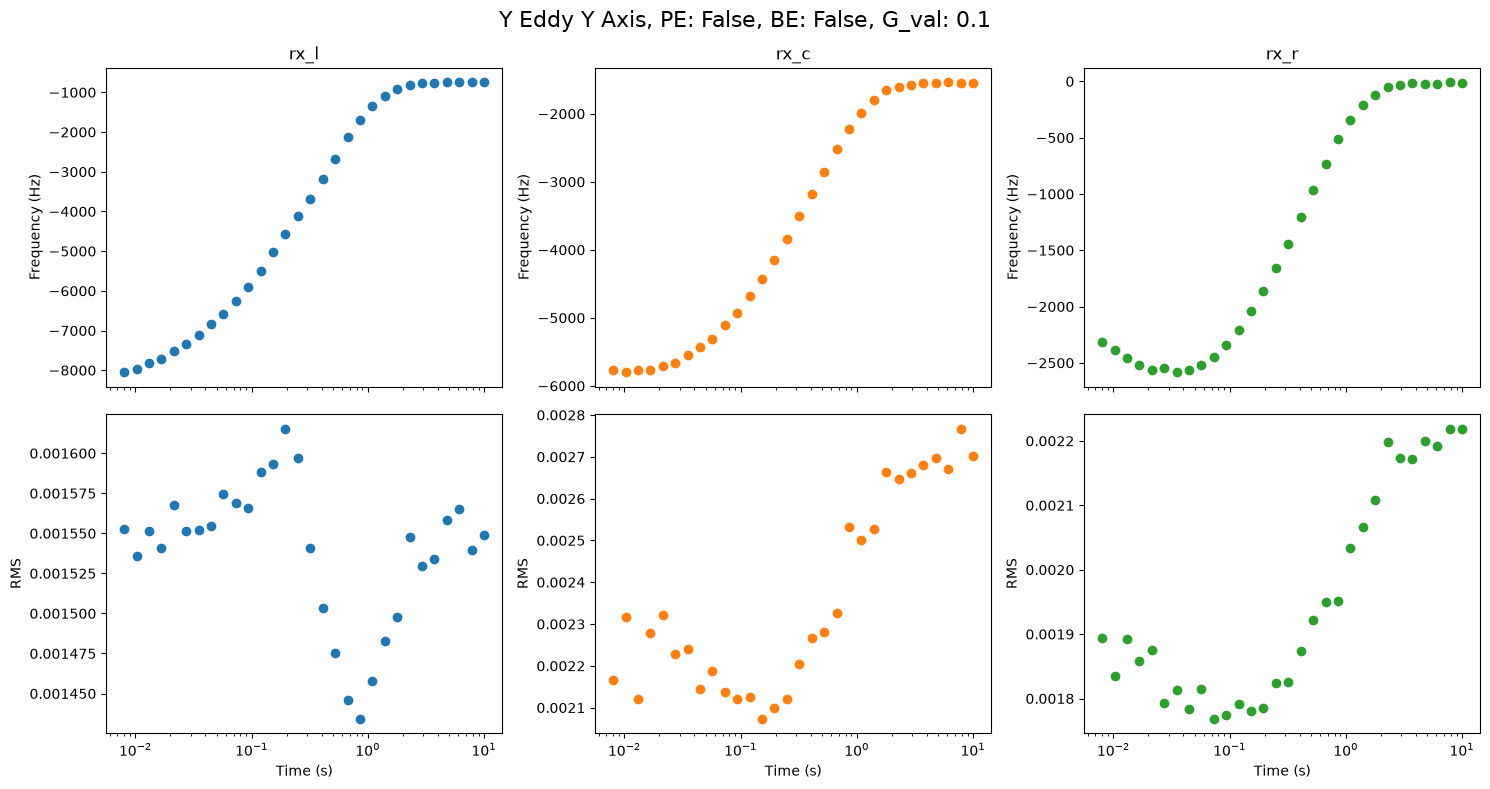

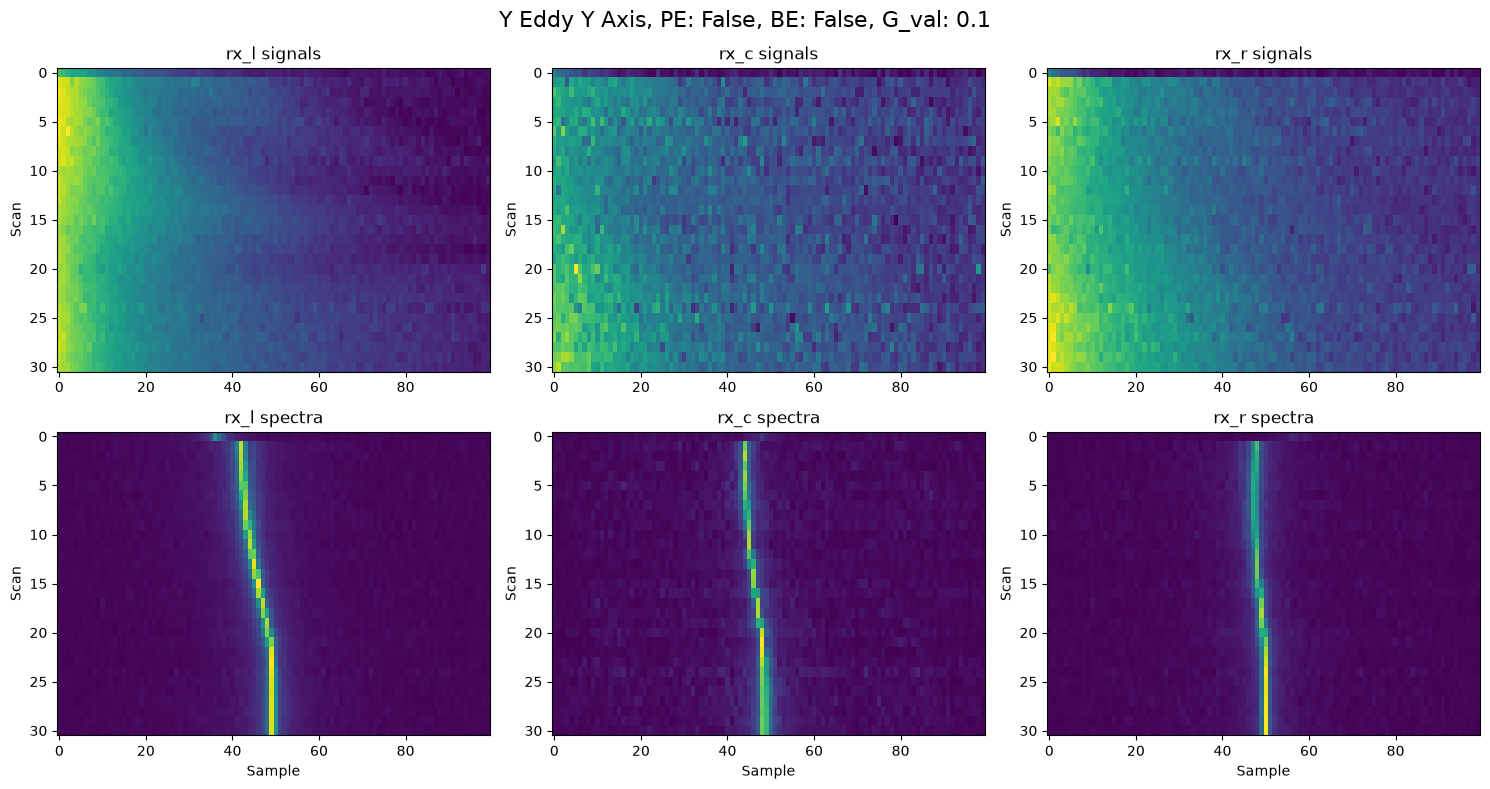

ParameterSet(n_scans=1, f=63637800.0, a_pulse=0.45, t_pulse=2.9999999999999997e-05, t_dw=1e-05, n_samples=100, n_pulses=30, t_acq_delay=0.0001, g_read=array([0. , 0.1, 0. ]), t_grad_spacing=1e-05, t_grad=10.0, t_ramp=0.001, t_wait=0.008, t_end=10.0, t_next=5.0, pre_emphasis=True, b0=True, offsets=array([0., 0., 0., 0.]), tx_chan=0, rx_chan_list=array([3., 0., 1.]), file_cals='C:\\Users\\halesda\\OneDrive - Victoria University of Wellington - STAFF\\Desktop\\kahu-workspace\\globals/', file_pars='C:\\Users\\halesda\\OneDrive - Victoria University of Wellington - STAFF\\Desktop\\kahu-workspace\\globals/', opt='n', compare='y', file_parsE='eddy_E_fit.yaml', file_parsB='eddy_B0_fit.yaml')


DEBUG:measure:file_parsE eddy_E_fit.yaml, file_parsB None
DEBUG:measure:Getting pars in file: file_parsE, eddy_E_fit.yaml
DEBUG:measure:file_parsE None, file_parsB eddy_B0_fit.yaml
DEBUG:measure:Getting pars in file: file_parsB, eddy_B0_fit.yaml
DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\globals/eddy_E_fit.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\globals/eddy_B0_fit.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2512957138938101 !!!!!!!!!!!!!!!!


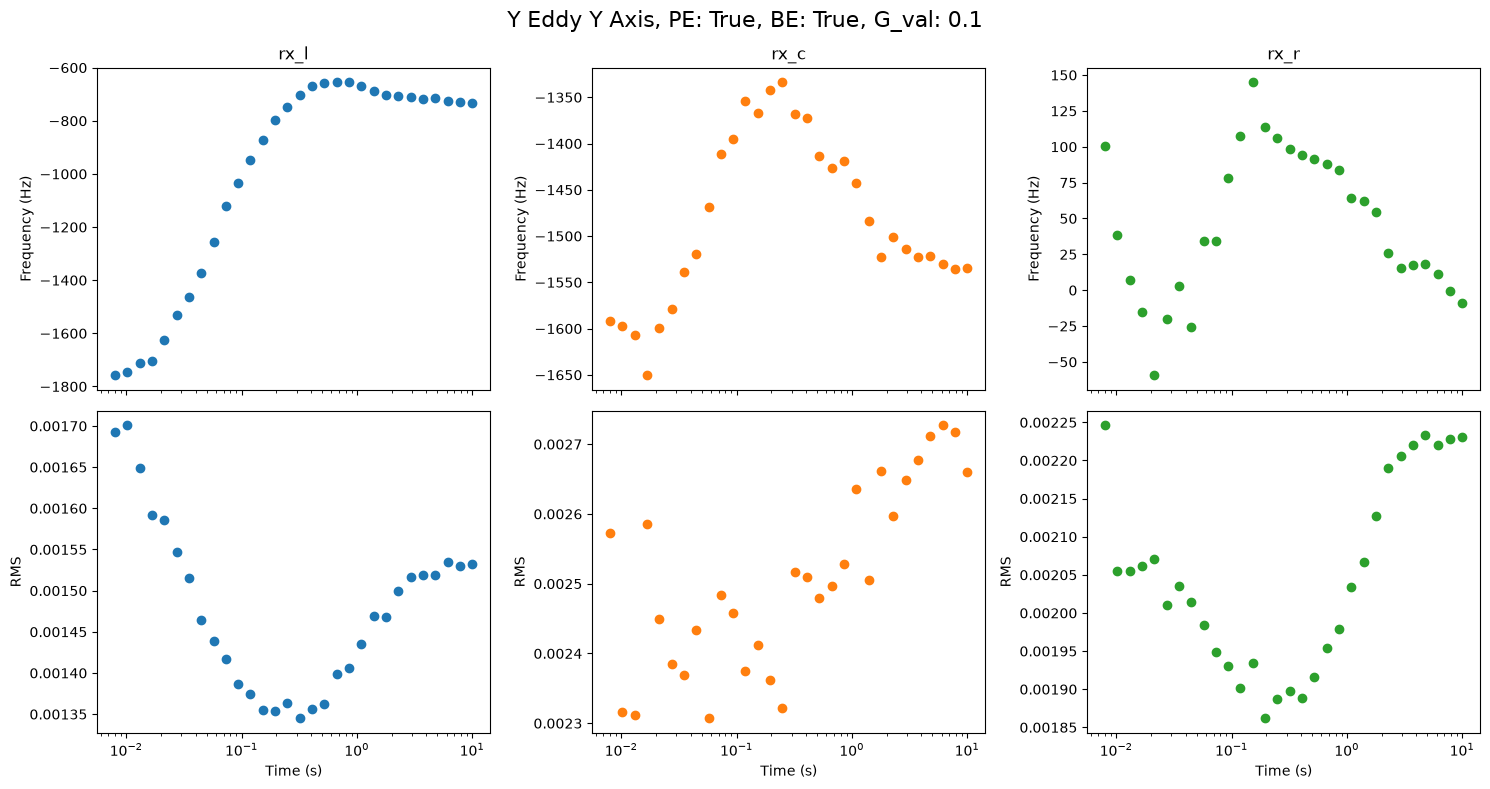

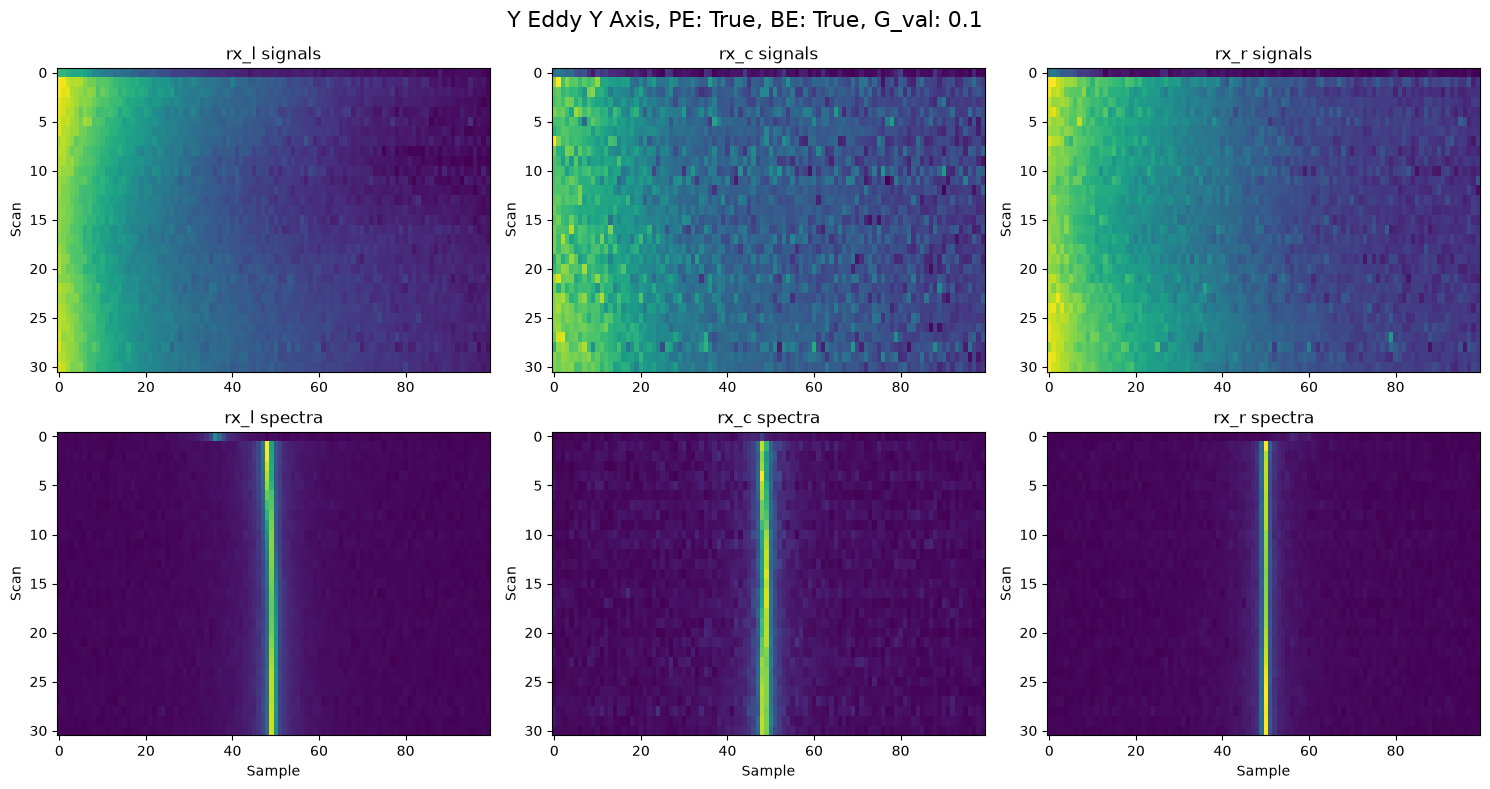

ParameterSet(n_scans=1, f=63637800.0, a_pulse=0.45, t_pulse=2.9999999999999997e-05, t_dw=1e-05, n_samples=100, n_pulses=30, t_acq_delay=0.0001, g_read=array([0. , 0.1, 0. ]), t_grad_spacing=1e-05, t_grad=10.0, t_ramp=0.001, t_wait=0.008, t_end=10.0, t_next=5.0, pre_emphasis=True, b0=True, offsets=array([0., 0., 0., 0.]), tx_chan=0, rx_chan_list=array([3., 0., 1.]), file_cals='C:\\Users\\halesda\\OneDrive - Victoria University of Wellington - STAFF\\Desktop\\kahu-workspace\\globals/', file_pars='C:\\Users\\halesda\\OneDrive - Victoria University of Wellington - STAFF\\Desktop\\kahu-workspace\\globals/', opt='n', compare='y', file_parsE='eddy_E.yaml', file_parsB='eddy_B0.yaml')


DEBUG:measure:file_parsE eddy_E.yaml, file_parsB None
DEBUG:measure:Getting pars in file: file_parsE, eddy_E.yaml
DEBUG:measure:file_parsE None, file_parsB eddy_B0.yaml
DEBUG:measure:Getting pars in file: file_parsB, eddy_B0.yaml


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\globals/eddy_E.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\globals/eddy_B0.yaml


DEBUG:measure:B0 uses pre-emphasised gradient
DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.24933762566776127 !!!!!!!!!!!!!!!!


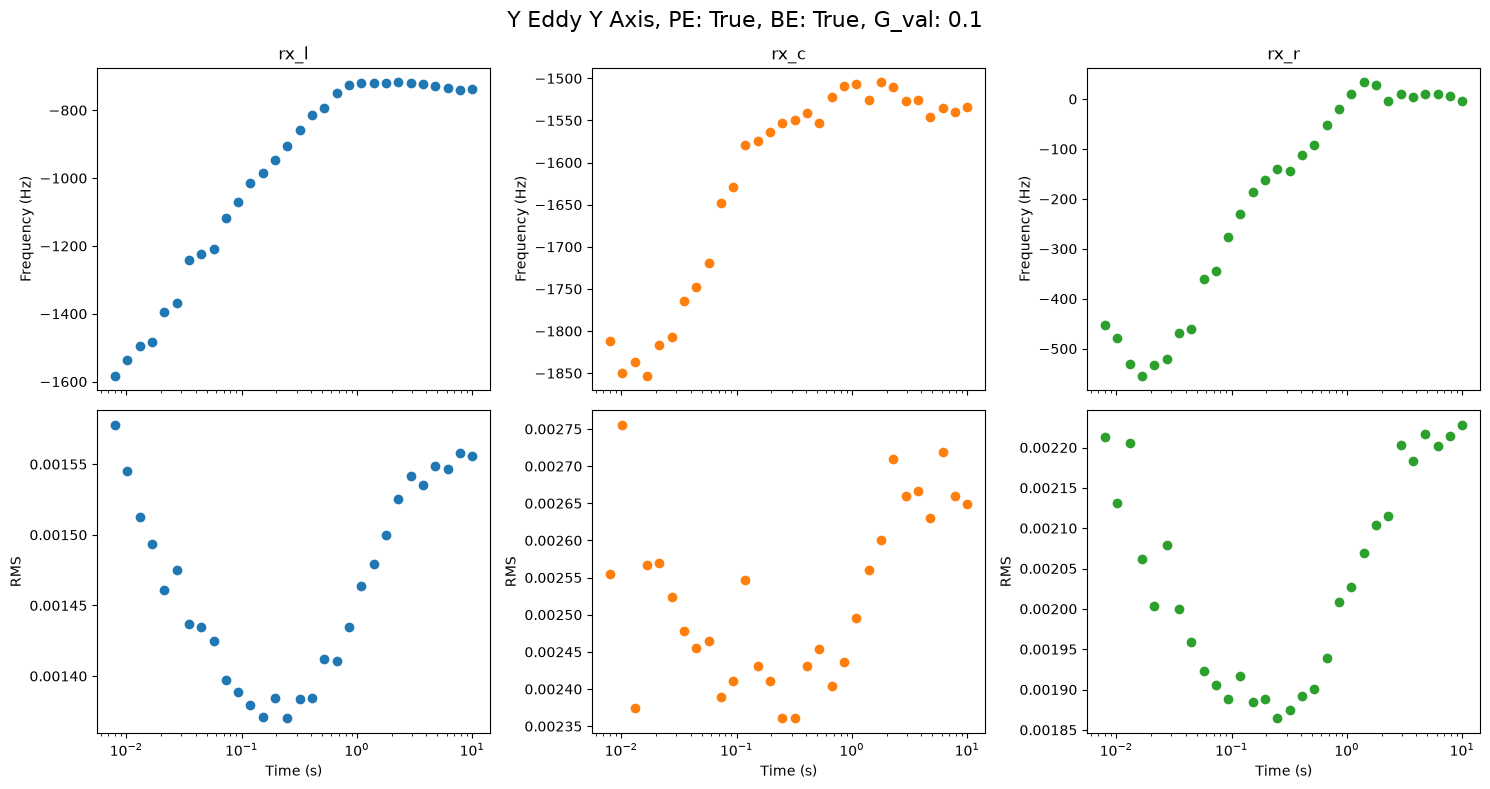

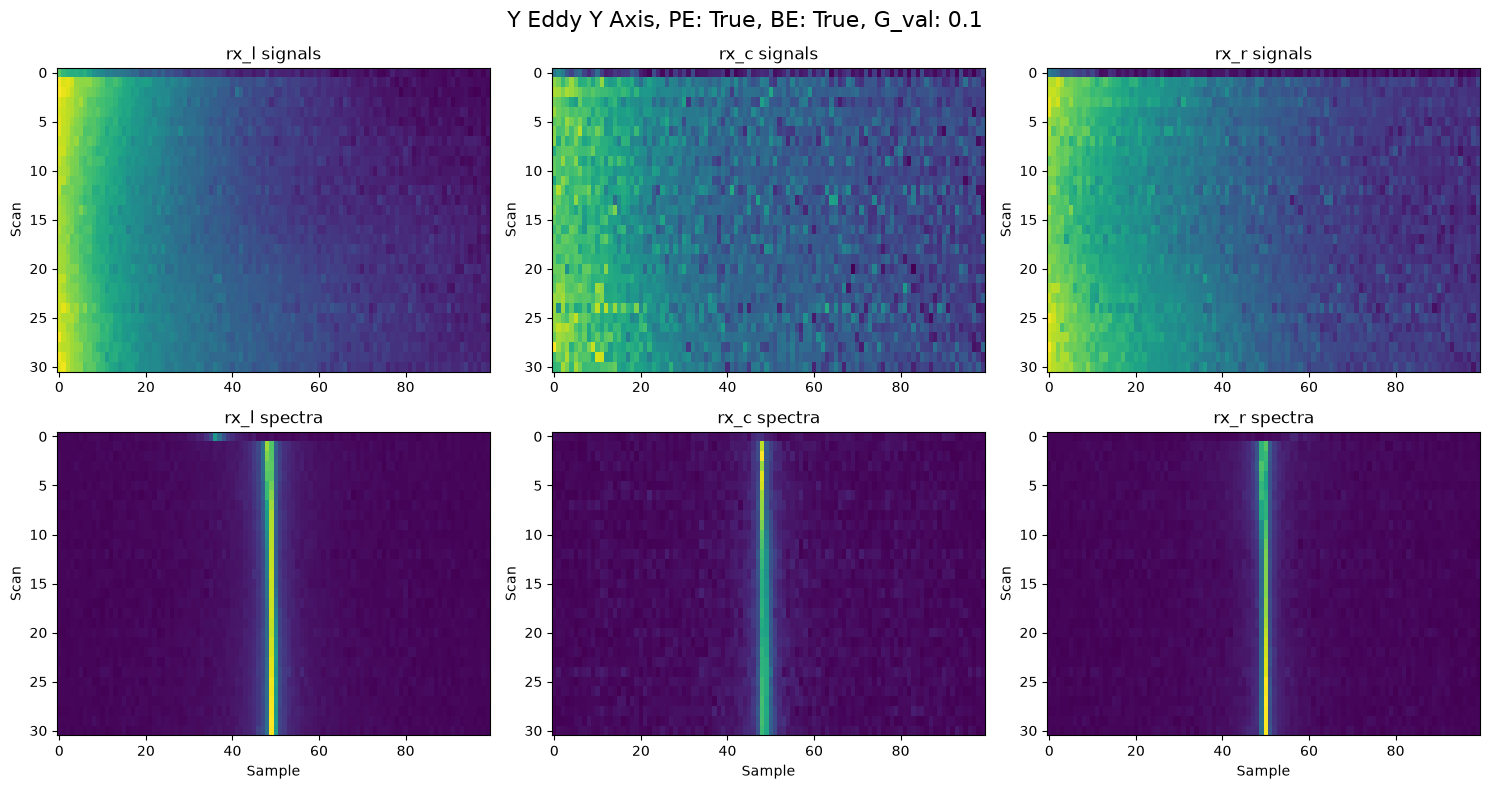

No Compensation, g_eddy max: 49.99333666500082 kHz/m       offset max: 4.25903714809262 kHz
Fitted Compensation, g_eddy max: 11.287689488589036 kHz/m       offset max: 0.19940029985007504 kHz
Gradient and B0 Optimised Compensation, g_eddy max: 3.888055972013991 kHz/m       offset max: 0.31667499583541575 kHz


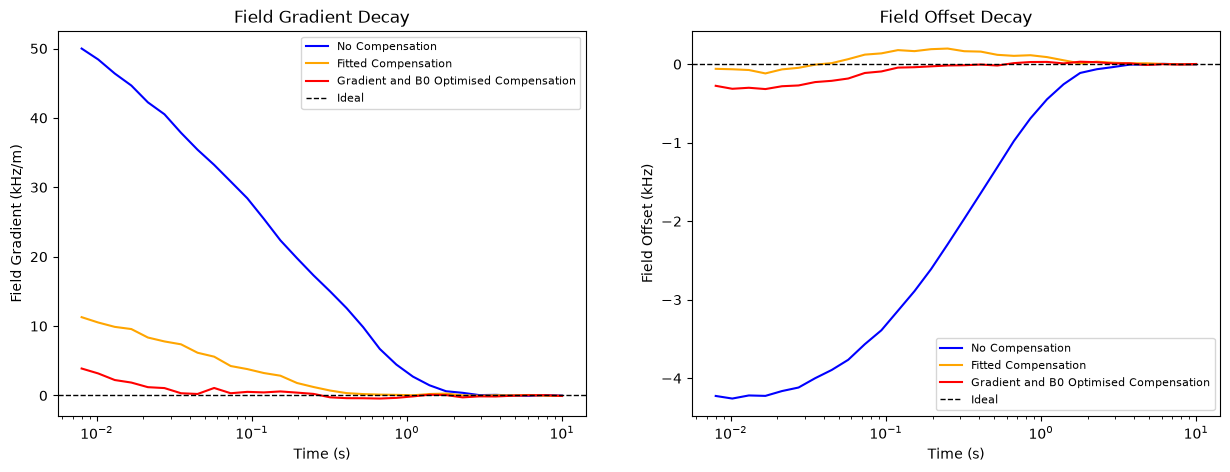

In [5]:
dict_, f_list = await comp.run_comparison(run_info, seq_params)

comp.plot_comparison(run_info, f_list, seq_params["OPT_AXIS"])

comp.save_pkl(dict_, seq_params["OPT_AXIS"])